# Product Intelligence

Compare normalized product codes by observed records and importer breadth. Product codes are kept as text, including leading zeros. Bar labels abbreviate long descriptions.

See the [release guide](../docs/TRADE_INTELLIGENCE_RELEASE.md) for the source and validation workflow.

In [1]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "notebook_support.py").is_file())
sys.path.insert(0, str(root / "notebooks"))
from notebook_support import BLUE, GOLD, TEAL, bar_chart, load_release, top

manifest, data = load_release('product_intelligence')
year = manifest["year"]
display(Markdown(f"**Dataset year:** {year}  |  **Release:** `{manifest['release_id']}`"))


**Dataset year:** 2024  |  **Release:** `ti-3349f6e0cb6dde75fe7d5323af71463748cad3232bc7bcb476c6ff6dcd8cd41b`

## Charts

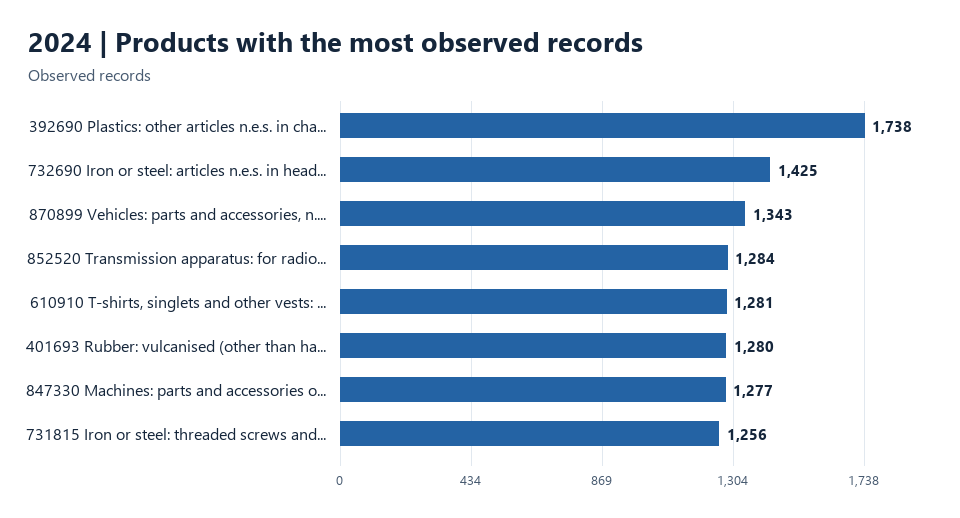

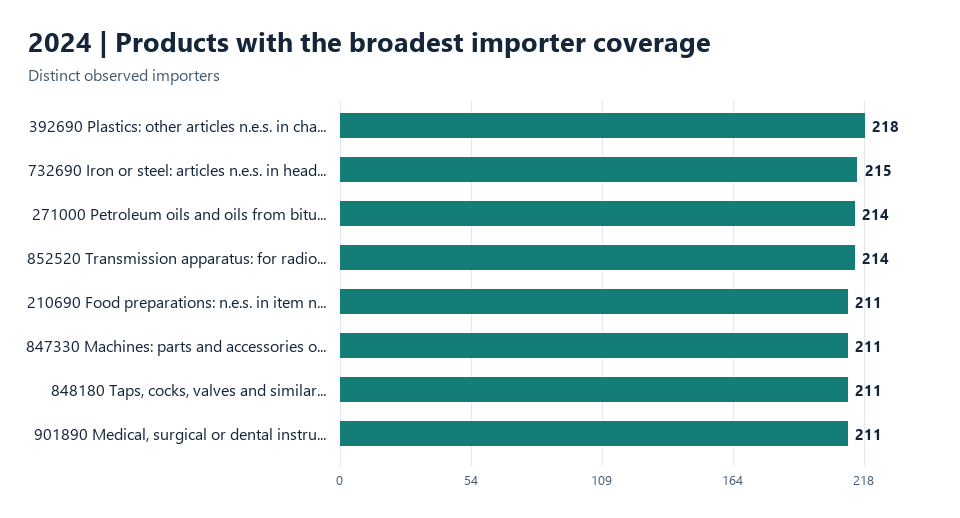

In [2]:
rows = data["records"]
record_leaders = top(rows, "record_count", lambda r: r["product_code"])
importer_leaders = top(rows, "importers", lambda r: r["product_code"])

def label(row):
    return f"{row['product_code']}  {row['description'] or '(reference description unavailable)'}"

display(bar_chart(f"{year} | Products with the most observed records", "Observed records",
                  [(label(r), r["record_count"]) for r in record_leaders], BLUE))
display(bar_chart(f"{year} | Products with the broadest importer coverage", "Distinct observed importers",
                  [(label(r), r["importers"]) for r in importer_leaders], TEAL))


## Analysis

In [3]:
coverage = data["reference_coverage"]
assert sum(r["record_count"] for r in rows) == manifest["statistics"]["eligible_records"]
lead, broad = record_leaders[0], importer_leaders[0]
display(Markdown(f'''
### What the charts show
- **{len(rows):,}** product profiles are in the processed release. **{coverage["mapped_products"]:,}** mapped to the supplied reference, **{coverage["unmapped_products"]:,}** were unmapped, and **{coverage["unobserved_reference_products"]:,}** reference codes had no observation in this extract.
- The top product by records is **`{lead["product_code"]}`** ({lead["description"]}), with **{lead["record_count"]:,}** records across **{lead["exporters"]}** exporters and **{lead["importers"]}** importers.
- The first product in the importer-breadth ranking is **`{broad["product_code"]}`** ({broad["description"]}), with **{broad["importers"]}** observed importers. The two charts measure different things: the number of eligible directional links and the number of distinct importing markets.
'''))



### What the charts show
- **4,577** product profiles are in the processed release. **4,577** mapped to the supplied reference, **0** were unmapped, and **445** reference codes had no observation in this extract.
- The top product by records is **`392690`** (Plastics: other articles n.e.s. in chapter 39), with **1,738** records across **29** exporters and **218** importers.
- The first product in the importer-breadth ranking is **`392690`** (Plastics: other articles n.e.s. in chapter 39), with **218** observed importers. The two charts measure different things: the number of eligible directional links and the number of distinct importing markets.


### Reading the results

The single-year export reached Excel's worksheet limit and has partial geographic coverage. Record counts measure observed keys in the extract. Currency, trade-value scale, quantity units and HS revision remain unverified. These charts use neither trade values nor quantities. Missing observations provide no evidence of market absence, and the extract cannot establish trends or future demand.
